In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
import sklearn.linear_model as LinearRegression
rcParams['font.family'] = 'STHeiti'

In [11]:
np.random.seed(42)
noise = np.random.randn(50) * 2
X = np.linspace(0, 10, 50)
y = 2 * X + 1 + noise
print(X)
print(y)
print(X.shape, y.shape)

[ 0.          0.20408163  0.40816327  0.6122449   0.81632653  1.02040816
  1.2244898   1.42857143  1.63265306  1.83673469  2.04081633  2.24489796
  2.44897959  2.65306122  2.85714286  3.06122449  3.26530612  3.46938776
  3.67346939  3.87755102  4.08163265  4.28571429  4.48979592  4.69387755
  4.89795918  5.10204082  5.30612245  5.51020408  5.71428571  5.91836735
  6.12244898  6.32653061  6.53061224  6.73469388  6.93877551  7.14285714
  7.34693878  7.55102041  7.75510204  7.95918367  8.16326531  8.36734694
  8.57142857  8.7755102   8.97959184  9.18367347  9.3877551   9.59183673
  9.79591837 10.        ]
[ 1.99342831  1.13163466  3.11170361  5.27054951  2.16434631  2.57254241
  6.60740522  5.39201232  3.32635735  5.75858947  4.15479727  4.55833641
  6.38188373  2.47956196  3.26445005  5.99787392  5.50495     8.56727018
  6.53089062  5.93049464 12.09456284  9.11987597 10.11464825  7.53825873
  9.70715292 11.42592681  9.31025774 12.7718042  11.22729405 12.25334719
 12.04148473 17.35761759 

In [7]:
def least_squares(x, y):
    x_mean, y_mean = np.mean(x), np.mean(y)
    w = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)
    b = y_mean - w * x_mean
    return w, b

w, b = least_squares(X, y)

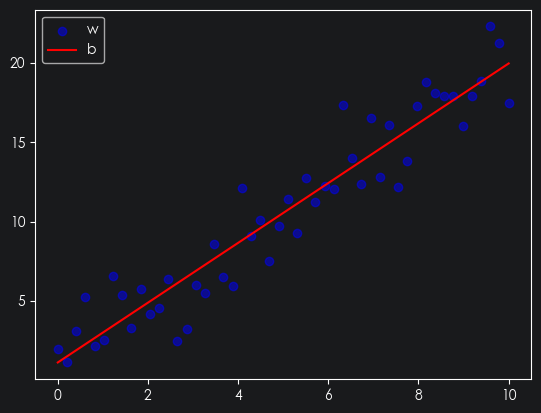

In [10]:
plt.scatter(X, y, color='blue', alpha=0.5)
plt.plot(X, w * X + b, color='red', alpha=1)
plt.legend(['w', 'b'])
plt.show()

一元线性模型

Epoch [200/1000] Loss: 3.3428 | w=3.0059, b=1.7932
Epoch [400/1000] Loss: 3.2389 | w=2.9402, b=2.2208
Epoch [600/1000] Loss: 3.2277 | w=2.9186, b=2.3614
Epoch [800/1000] Loss: 3.2265 | w=2.9115, b=2.4076
Epoch [1000/1000] Loss: 3.2264 | w=2.9092, b=2.4228

最终结果: w=2.9092, b=2.4228  (真实值 w=3, b=2)


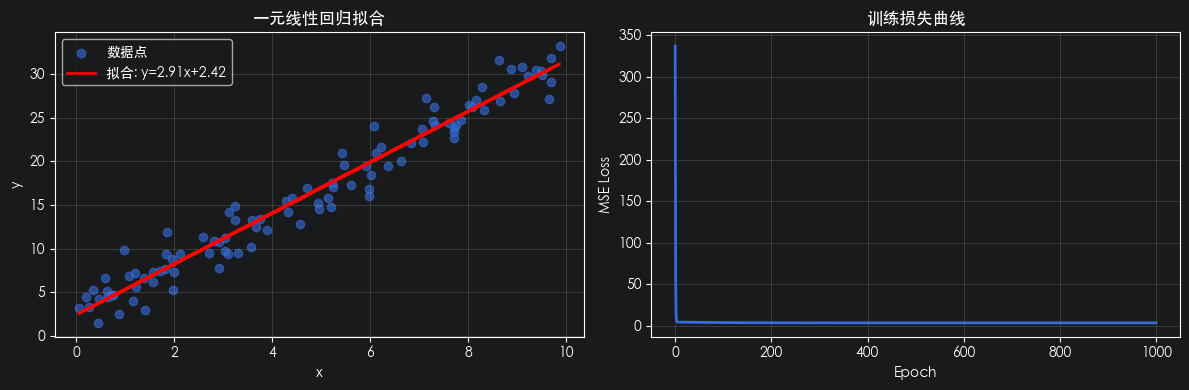

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 数据准备
np.random.seed(42)
n = 100
X = np.random.rand(n) * 10                        # 100个样本，范围[0,10]
y = 3 * X + 2 + np.random.randn(n) * 2            # 真实规律 y = 3x + 2 + 噪声

# 2. 模型设计：参数初始化
w = 0.0   # 权重
b = 0.0   # 偏置

# 3. 损失函数与优化器
def mse_loss(y_pred, y_true):
    """均方误差"""
    return np.mean((y_pred - y_true) ** 2)

def gradients(X, y_pred, y_true):
    """计算 w 和 b 的梯度"""
    n = len(y_true)
    error = y_pred - y_true
    dw = (2 / n) * np.sum(error * X)      # ∂L/∂w
    db = (2 / n) * np.sum(error)          # ∂L/∂b
    return dw, db

# 4. 模型训练（梯度下降）
lr = 0.01
epochs = 1000
loss_history = []

for epoch in range(epochs):
    # 前向传播
    y_pred = w * X + b
    loss = mse_loss(y_pred, y)

    # 反向传播：计算梯度
    dw, db = gradients(X, y_pred, y)

    # 参数更新
    w -= lr * dw
    b -= lr * db

    loss_history.append(loss)
    if (epoch + 1) % 200 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] Loss: {loss:.4f} | w={w:.4f}, b={b:.4f}")

print(f"\n最终结果: w={w:.4f}, b={b:.4f}  (真实值 w=3, b=2)")


# 5. 可视化
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 图1：拟合直线
axes[0].scatter(X, y, alpha=0.6, label='数据点')
axes[0].plot(X, w * X + b, color='red', linewidth=2, label=f'拟合: y={w:.2f}x+{b:.2f}')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_title('一元线性回归拟合')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 图2：损失曲线
axes[1].plot(loss_history, linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MSE Loss')
axes[1].set_title('训练损失曲线')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

多元线性回归
方法：
1. 正规方程
2. 梯度下降

正规方程解:
  w = [ 1.78012023 -1.49254126  0.8148524 ], b = 1.5813
  （标准化后的 w，原始 w = [ 1.99761626 -1.49076303  0.81185447]）

梯度下降解:
  w = [ 1.78012023 -1.49254126  0.8148524 ], b = 1.5813

梯度下降 - MSE: 0.0101, R²: 0.9983


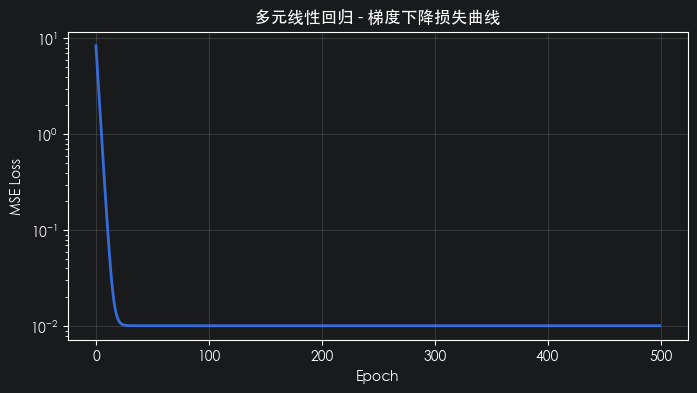

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 数据准备：生成 3 个特征的线性数据
np.random.seed(42)
n, d = 200, 3

X = np.random.randn(n, d)                              # (200, 3)
true_w = np.array([2.0, -1.5, 0.8])
true_b = 1.2
y = X @ true_w + true_b + np.random.randn(n) * 0.1     # 加小噪声

# 特征标准化（梯度下降对量纲敏感，标准化能加速收敛）
X_mean, X_std = X.mean(axis=0), X.std(axis=0)
X_norm = (X - X_mean) / X_std

# 2. 方法A：正规方程（闭式解）
# 把 b 吸收进 w：给 X 加一列全 1
X_b = np.c_[X_norm, np.ones(n)]                        # (200, 4)
# w = (X^T X)^{-1} X^T y
w_closed = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

print("正规方程解:")
print(f"  w = {w_closed[:d]}, b = {w_closed[-1]:.4f}")
print(f"  （标准化后的 w，原始 w = {w_closed[:d] / X_std}）")


# 3. 方法B：梯度下降（手写）
def train_gd(X, y, lr=0.1, epochs=500):
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    losses = []

    for epoch in range(epochs):
        # 前向
        y_pred = X @ w + b
        error = y_pred - y

        # 梯度
        dw = (2 / n) * (X.T @ error)
        db = (2 / n) * np.sum(error)

        # 更新
        w -= lr * dw
        b -= lr * db

        losses.append(np.mean(error ** 2))

    return w, b, losses

w_gd, b_gd, losses = train_gd(X_norm, y, lr=0.1, epochs=500)

print("\n梯度下降解:")
print(f"  w = {w_gd}, b = {b_gd:.4f}")


# 4. 评估：均方误差和 R²
def evaluate(X, y, w, b):
    y_pred = X @ w + b
    mse = np.mean((y_pred - y) ** 2)
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return mse, r2

mse_gd, r2_gd = evaluate(X_norm, y, w_gd, b_gd)
print(f"\n梯度下降 - MSE: {mse_gd:.4f}, R²: {r2_gd:.4f}")

# 5. 可视化
plt.figure(figsize=(8, 4))
plt.plot(losses, linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('多元线性回归 - 梯度下降损失曲线')
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.show()